<a href="https://colab.research.google.com/github/athfizh/PemMes26_05_Hafizh/blob/main/JS07/JS07-03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---


# **Klasterisasi - Lab 3**


---

---


# **Langkah 0 - Import Library**


---

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

> `matplotlib.pyplot` dipakai untuk menampilkan citra dan scatter plot warna, `numpy` untuk operasi array (normalisasi, reshape, dan pengambilan subset acak), sedangkan `seaborn` diimpor untuk kebutuhan visualisasi (pada notebook ini belum dipakai). Semua library sudah tersedia di Google Colab.

---


# **Langkah 1 - Load Data Citra**


---

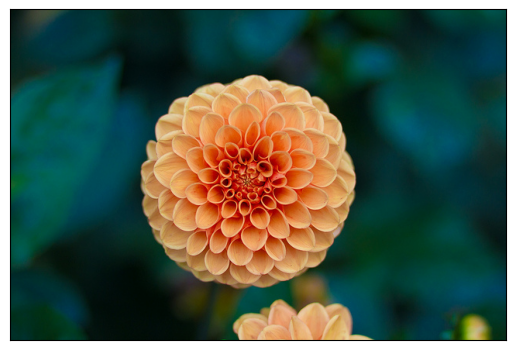

In [2]:
from sklearn.datasets import load_sample_image
flower = load_sample_image("flower.jpg")
ax = plt.axes(xticks=[], yticks=[])
ax.imshow(flower)

> `load_sample_image("flower.jpg")` memuat citra contoh yang sudah disertakan di dalam scikit-learn, jadi tidak perlu mengunggah file sendiri. Citra tersimpan sebagai array NumPy berukuran tinggi x lebar x 3, dengan nilai tiap kanal warna 0-255. `plt.axes(xticks=[], yticks=[])` membuat area plot tanpa sumbu, lalu `imshow()` menampilkannya sebagai gambar. Citra ini yang nantinya akan dikompresi warnanya.

---


# **Langkah 2 - Preprocessing**


---

In [3]:
# Check shape
print(flower.shape)

# Normalize color
data = flower / 255.0

# Reshape
data = data.reshape(427 * 640, 3) # turn to 1D

print(data.shape)

(427, 640, 3)
(273280, 3)


> `flower.shape` menghasilkan `(427, 640, 3)`, artinya citra berukuran 427 piksel x 640 piksel dengan 3 kanal warna, sehingga total ada 427 x 640 = 273.280 piksel. Pembagian dengan `255.0` menormalisasi nilai warna ke rentang 0-1 agar skalanya seragam dan lebih mudah dihitung jaraknya. `reshape(427 * 640, 3)` mengubah citra menjadi matriks 273.280 baris x 3 kolom, yaitu satu baris berisi satu piksel dengan tiga nilai R, G, B. Bentuk inilah yang dibutuhkan algoritma klasterisasi, karena setiap piksel diperlakukan sebagai satu titik data.

---


# **Langkah 3 - Cek Sebaran Warna**


---

In [4]:
def plot_pixels(data, title, colors=None, N=10000):
    if colors is None:
        colors = data

    # choose a random subset
    rng = np.random.RandomState(0)
    i = rng.permutation(data.shape[0])[:N]
    colors = colors[i]
    R, G, B = data[i].T

    fig, ax = plt.subplots(1, 2, figsize=(16, 6))
    ax[0].scatter(R, G, color=colors, marker='.')
    ax[0].set(xlabel='Red', ylabel='Green', xlim=(0, 1), ylim=(0, 1))

    ax[1].scatter(R, B, color=colors, marker='.')
    ax[1].set(xlabel='Red', ylabel='Blue', xlim=(0, 1), ylim=(0, 1))

    fig.suptitle(title, size=20);

> Fungsi `plot_pixels()` menerima data piksel dan judul, lalu memilih maksimal 10.000 piksel secara acak (`N=10000`) dengan `RandomState(0)` agar hasilnya konsisten. Sampel diambil karena memplot 273.280 titik sekaligus akan lambat dan saling menutupi. Dua subplot dibuat: kiri memplot nilai Red vs Green dan kanan Red vs Blue, dengan `color=colors` sehingga tiap titik diwarnai sesuai warna aslinya. Parameter `colors` nantinya diisi warna hasil kompresi agar sebarannya bisa dibandingkan dengan warna asli.

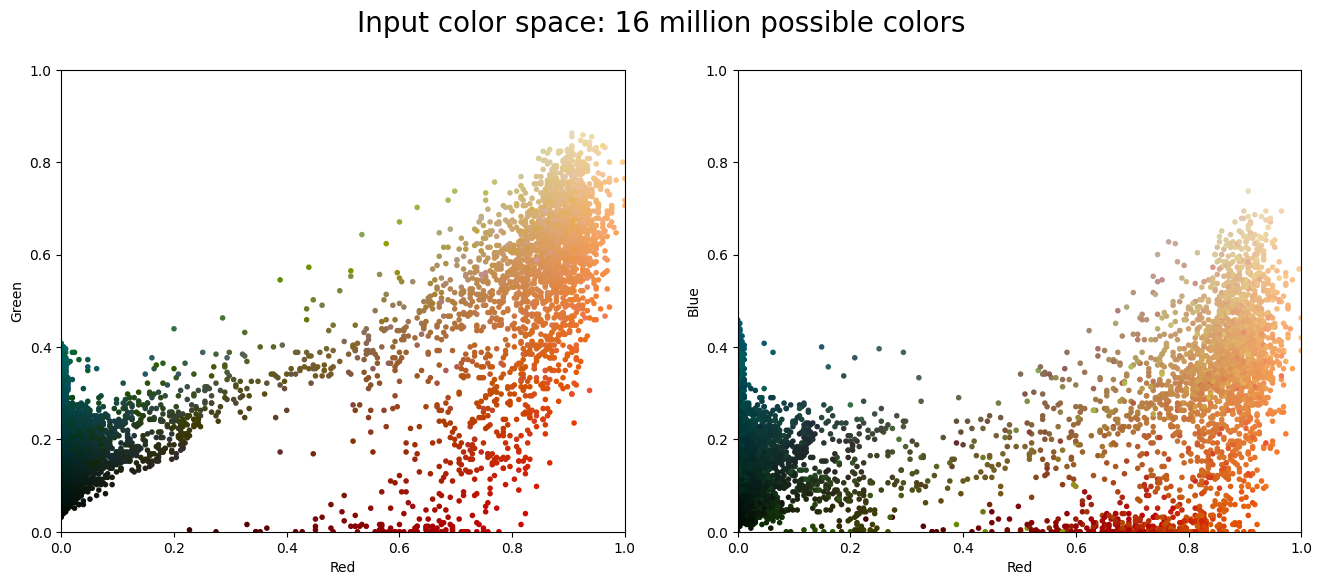

In [5]:
plot_pixels(data, title='Input color space: 16 million possible colors')

> Pemanggilan `plot_pixels(data, ...)` menampilkan sebaran warna asli citra. Terlihat titik-titik tersebar cukup merata dan membentuk pola memanjang, karena citra asli memakai 8 bit per kanal sehingga tersedia 256 x 256 x 256 = sekitar 16 juta kemungkinan warna. Sebagian besar titik mengumpul di area tertentu (warna hijau kebiruan dan oranye kemerahan), yang merupakan warna dominan pada citra bunga tersebut.

---


# **Langkah 4 - Klasterisasi Warna**


---

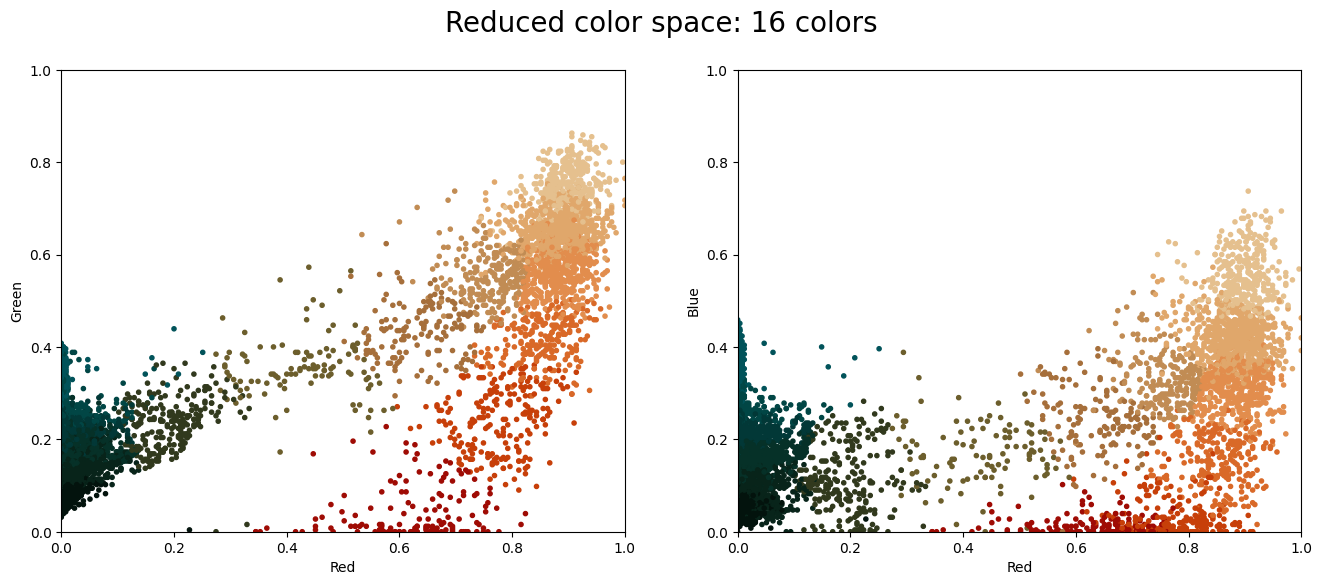

In [6]:
from sklearn.cluster import MiniBatchKMeans

kmeans = MiniBatchKMeans(16)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

plot_pixels(data, colors=new_colors,title="Reduced color space: 16 colors")

> `MiniBatchKMeans(16)` membuat model K-Means dengan 16 klaster yang dilatih memakai mini-batch, yaitu sebagian data per iterasi, sehingga jauh lebih cepat dan hemat memori dibanding `KMeans` biasa untuk ratusan ribu piksel. `fit(data)` mencari 16 warna pusat (centroid) yang paling mewakili seluruh piksel. `predict(data)` menentukan klaster tiap piksel, lalu `cluster_centers_[...]` mengganti warna setiap piksel dengan warna centroid klasternya. Hasilnya `new_colors` berisi 273.280 warna baru yang hanya diambil dari 16 warna, dan grafik kanan menampilkan sebaran warnanya yang jauh lebih rapat. Karena pemilihan centroid awal acak, hasil antar-run bisa sedikit berbeda.

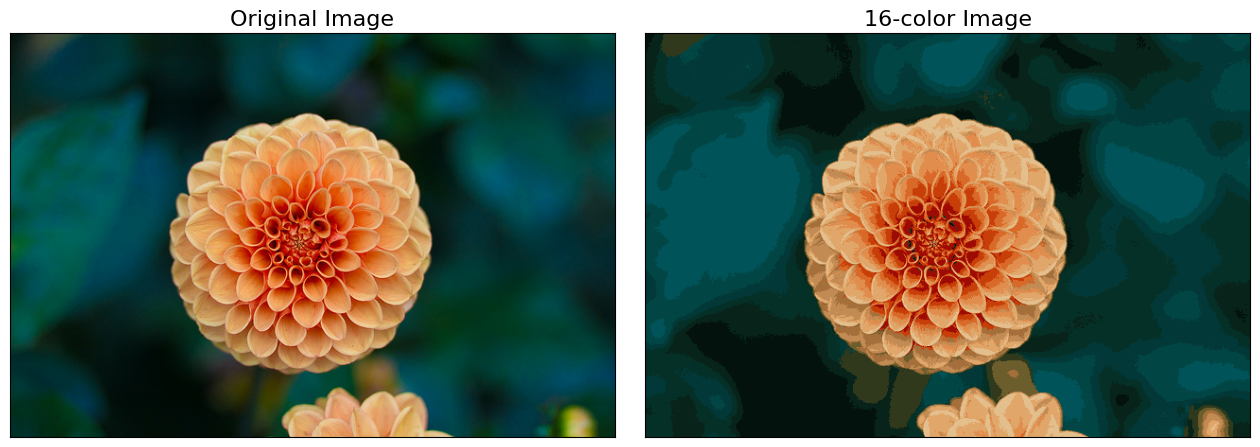

In [7]:
flower_recolored = new_colors.reshape(flower.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(flower)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(flower_recolored)
ax[1].set_title('16-color Image', size=16);

> `new_colors.reshape(flower.shape)` mengubah kembali matriks 273.280 x 3 menjadi citra 427 x 640 x 3, lalu kedua citra ditampilkan berdampingan: asli di kiri dan hasil 16 warna di kanan. Secara visual hasilnya hampir mirip dengan aslinya, hanya muncul efek blok warna pada area gradasi. Secara data, tiap piksel asli butuh 24 bit (8 bit per kanal) atau sekitar 820 KB untuk 273.280 piksel, sedangkan versi 16 warna hanya butuh 4 bit per piksel untuk indeks palet ditambah 16 x 24 bit untuk tabel warna, sehingga ukurannya jauh lebih kecil. Inilah inti kompresi warna dengan klasterisasi.